# Manutenção de máquinas a partir de sensores IoT

Prever se uma máquina precisa de manutenção (`VARIAVEL_ALVO = 1`) ou não (`0`),
usando 178 leituras de sensores. Os dados são fictícios: 11.500 linhas.

O fluxo é o mesmo do `Projeto3.ipynb`, em menos células:

1. olhar o alvo e a prevalência
2. separar treino, validação e teste (70/15/15) com semente fixa
3. equilibrar só o treino (undersampling)
4. padronizar com o scaler ajustado no treino
5. comparar regressão logística, Naive Bayes e XGBoost
6. escolher pelo AUC de validação, gravar o modelo e avaliar no teste
7. aplicar o modelo em `novos_dados.csv`

In [18]:
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

SEED = 64
LIMIAR = 0.5
N_SENSORES = 178
ALVO = "VARIAVEL_ALVO"
# RTX 3050. A busca usa um modelo por vez: vários processos na mesma GPU estouram a memória.
XGB = dict(device="cuda", tree_method="hist", random_state=SEED)

## Dados

Cada linha é uma máquina. As 178 primeiras colunas são sensores; a última é o alvo.
Prevalência é a fração de máquinas que precisaram de manutenção.

In [19]:
df = pd.read_csv("dataset.csv")
sensores = df.columns[:N_SENSORES].tolist()
assert ALVO in df.columns
assert sensores.count(ALVO) == 0
assert df[sensores].columns.is_unique
assert df.isna().sum().sum() == 0

df = df[sensores + [ALVO]]
print("shape:", df.shape)
print("prevalência: %.3f" % (df[ALVO].mean()))
df.head()

shape: (11500, 179)
prevalência: 0.200


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X170,X171,X172,X173,X174,X175,X176,X177,X178,VARIAVEL_ALVO
0,135,190,229,223,192,125,55,-9,-33,-38,...,-17,-15,-31,-77,-103,-127,-116,-83,-51,0
1,386,382,356,331,320,315,307,272,244,232,...,164,150,146,152,157,156,154,143,129,1
2,-32,-39,-47,-37,-32,-36,-57,-73,-85,-94,...,57,64,48,19,-12,-30,-35,-35,-36,0
3,-105,-101,-96,-92,-89,-95,-102,-100,-87,-79,...,-82,-81,-80,-77,-85,-77,-72,-69,-65,0
4,-9,-65,-98,-102,-78,-48,-16,0,-21,-59,...,4,2,-12,-32,-41,-65,-83,-89,-73,0


## Divisão e balanceamento

A divisão aleatória usa `random_state` para o mesmo resultado em outra execução.
Validação e teste ficam com a prevalência real: servem para medir o modelo no mundo,
não para ensiná-lo.

O treino é equilibrado por undersampling: as duas classes ficam com o mesmo tamanho.
Isso evita um modelo que só aprende a dizer "não precisa de manutenção".
O custo é jogar fora parte da classe majoritária.

In [20]:
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

holdout = df.sample(frac=0.30, random_state=SEED)
teste = holdout.sample(frac=0.50, random_state=SEED)
validacao = holdout.drop(teste.index)
treino = df.drop(holdout.index)

assert len(df) == len(treino) + len(validacao) + len(teste)

positivos = treino[treino[ALVO] == 1]
negativos = treino[treino[ALVO] == 0]
n = min(len(positivos), len(negativos))
treino_eq = pd.concat(
    [
        positivos.sample(n=n, random_state=SEED),
        negativos.sample(n=n, random_state=SEED),
    ],
    ignore_index=True,
).sample(frac=1, random_state=SEED).reset_index(drop=True)

for nome, parte in ("treino", treino), ("treino equilibrado", treino_eq), ("validação", validacao), ("teste", teste):
    print("%s n=%d prevalência=%.3f" % (nome, len(parte), parte[ALVO].mean()))

treino.to_csv("dados_treino.csv", index=False)
treino_eq.to_csv("dados_treino_final.csv", index=False)
validacao.to_csv("dados_valid.csv", index=False)
teste.to_csv("dados_teste.csv", index=False)
pickle.dump(sensores, open("cols_input.sav", "wb"))

treino n=8050 prevalência=0.203
treino equilibrado n=3274 prevalência=0.500
validação n=1725 prevalência=0.206
teste n=1725 prevalência=0.178


## Padronização

`StandardScaler` tira a média e divide pelo desvio de cada sensor, usando só o treino
equilibrado. Validação, teste e dados novos recebem a mesma transformação.
Sem isso, a regressão logística trata sensores de escala maior como mais importantes.

In [22]:
def matriz(parte):
    return parte[sensores].to_numpy(), parte[ALVO].to_numpy()


X_treino, y_treino = matriz(treino_eq)
X_valid, y_valid = matriz(validacao)
X_teste, y_teste = matriz(teste)

scaler = StandardScaler().fit(X_treino)
X_treino = scaler.transform(X_treino)
X_valid = scaler.transform(X_valid)
X_teste = scaler.transform(X_teste)
pickle.dump(scaler, open("scaler.sav", "wb"))
print(X_treino.shape, X_valid.shape, X_teste.shape)

(3274, 178) (1725, 178) (1725, 178)


## Métricas

O modelo devolve uma probabilidade. Acima de 0,5 a máquina é classificada como
"precisa de manutenção", o ponto natural depois do balanceamento 50/50.

- **AUC**: separa as classes em qualquer limiar. 0,5 é chute; 1 é separação perfeita.
- **Acurácia**: fração de acertos. Engana quando uma classe domina.
- **Recall**: das máquinas que precisavam de manutenção, quantas o modelo pegou.
- **Precisão**: das máquinas marcadas para manutenção, quantas realmente precisavam.
- **Especificidade**: das máquinas saudáveis, quantas o modelo deixou em paz.

In [23]:
def metricas(y, proba, limiar=LIMIAR):
    previsto = proba >= limiar
    tn, fp, fn, tp = confusion_matrix(y, previsto).ravel()
    return {
        "auc": roc_auc_score(y, proba),
        "acuracia": accuracy_score(y, previsto),
        "recall": recall_score(y, previsto),
        "precisao": precision_score(y, previsto, zero_division=0),
        "especificidade": tn / (tn + fp),
    }


def avaliar(nome, modelo, X_tr, y_tr, X_va, y_va):
    print("\n%s" % nome)
    linhas = []
    for conjunto, X, y in ("treino", X_tr, y_tr), ("validação", X_va, y_va):
        valores = metricas(y, modelo.predict_proba(X)[:, 1])
        print("  %s  %s" % (conjunto, "  ".join("%s=%.3f" % item for item in valores.items())))
        linhas.append({"classificador": nome, "conjunto": conjunto, **valores})
    return linhas


resultados = []
modelos = {
    "Regressão logística": LogisticRegression(max_iter=500, random_state=SEED),
    "Naive Bayes": GaussianNB(),
    "XGBoost": XGBClassifier(**XGB),
}
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    resultados.extend(avaliar(nome, modelo, X_treino, y_treino, X_valid, y_valid))


Regressão logística
  treino  auc=0.628  acuracia=0.663  recall=0.541  precisao=0.716  especificidade=0.785
  validação  auc=0.520  acuracia=0.721  recall=0.449  precisao=0.359  especificidade=0.791

Naive Bayes
  treino  auc=0.984  acuracia=0.932  recall=0.891  precisao=0.970  especificidade=0.973
  validação  auc=0.988  acuracia=0.966  recall=0.916  precisao=0.918  especificidade=0.979

XGBoost
  treino  auc=1.000  acuracia=1.000  recall=1.000  precisao=1.000  especificidade=1.000
  validação  auc=0.995  acuracia=0.964  recall=0.961  precisao=0.877  especificidade=0.965


c:\Users\fabri\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\core.py:569: UserWarning: [15:10:09] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


## XGBoost: validação cruzada e busca de hiperparâmetros

A validação cruzada parte o treino equilibrado em 5 fatias e mede o AUC em cada uma.
A média diz se o XGBoost se sustenta dentro do treino, antes de olhar a validação.

O `GridSearchCV` testa combinações de profundidade, taxa de aprendizado, número de
árvores e fração de linhas (`subsample`). O critério continua sendo o AUC.
São 81 combinações × 5 fatias. Cada XGBoost roda na GPU (`device="cuda"`).
`n_jobs=1` de propósito: a RTX 3050 tem 6 GB e não aguenta vários treinos ao mesmo tempo.

In [24]:
cv = cross_val_score(
    XGBClassifier(**XGB),
    X_treino,
    y_treino,
    cv=5,
    scoring="roc_auc",
)
print("AUC por fatia:", np.round(cv, 3))
print("média: %.3f" % cv.mean())

AUC por fatia: [0.991 0.989 0.993 0.994 0.994]
média: 0.992


In [25]:
grade = {
    "max_depth": [3, 4, 5],
    "learning_rate": [0.01, 0.1, 0.2],
    "n_estimators": [100, 200, 300],
    "subsample": [0.7, 0.8, 0.9],
}
busca = GridSearchCV(
    XGBClassifier(**XGB),
    grade,
    cv=5,
    scoring="roc_auc",
    n_jobs=1,
)
busca.fit(X_treino, y_treino)
print("melhores hiperparâmetros:", busca.best_params_)

melhor = busca.best_estimator_
resultados.extend(avaliar("XGBoost otimizado", melhor, X_treino, y_treino, X_valid, y_valid))

melhores hiperparâmetros: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.8}

XGBoost otimizado
  treino  auc=1.000  acuracia=1.000  recall=1.000  precisao=1.000  especificidade=1.000
  validação  auc=0.995  acuracia=0.966  recall=0.963  precisao=0.884  especificidade=0.967


## Escolha

O AUC de validação compara modelos diferentes no mesmo conjunto, que o treino não viu.
O gráfico mostra treino e validação lado a lado: treino muito acima de validação
é sinal de decorar os dados.

      classificador  conjunto      auc  acuracia   recall  precisao  especificidade
  XGBoost otimizado validação 0.995045  0.966377 0.963483  0.884021        0.967129
            XGBoost validação 0.994825  0.964058 0.960674  0.876923        0.964938
        Naive Bayes validação 0.988234  0.965797 0.915730  0.918310        0.978817
Regressão logística validação 0.520418  0.720580 0.449438  0.358744        0.791088


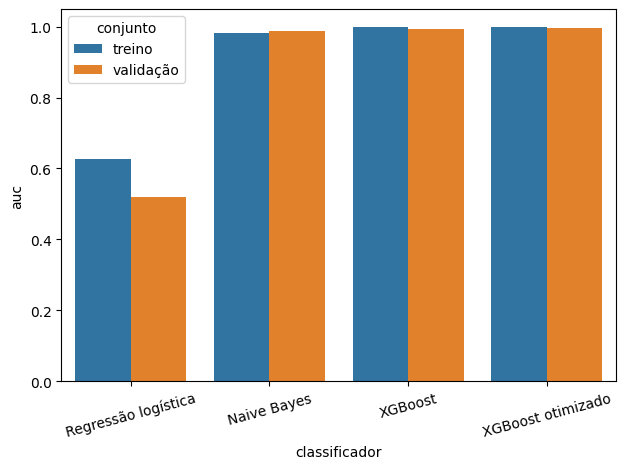

escolhido pelo AUC de validação: XGBoost otimizado


In [26]:
df_resultados = pd.DataFrame(resultados)
tabela = (
    df_resultados[df_resultados["conjunto"] == "validação"]
    .sort_values("auc", ascending=False)
    .reset_index(drop=True)
)
print(tabela.to_string(index=False))

sns.barplot(data=df_resultados, x="classificador", y="auc", hue="conjunto")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

escolhido = tabela.iloc[0]["classificador"]
print("escolhido pelo AUC de validação:", escolhido)
pickle.dump(melhor, open("melhor_modelo_dsa.pkl", "wb"), protocol=4)

## Teste

O teste ficou guardado até aqui. As três curvas ROC usam o XGBoost otimizado,
que é o candidato da busca. Se outro modelo ganhar a tabela, a gravação acima
ainda é a desse XGBoost: a grade só otimiza ele, como no notebook original.

O treino plotado aqui é o equilibrado, o mesmo em que o modelo aprendeu.

treino {'auc': 1.0, 'acuracia': 1.0, 'recall': 1.0, 'precisao': 1.0, 'especificidade': np.float64(1.0)}
validação {'auc': 0.9950447714644497, 'acuracia': 0.9663768115942029, 'recall': 0.9634831460674157, 'precisao': 0.884020618556701, 'especificidade': np.float64(0.9671292914536158)}
teste {'auc': 0.9930534817584983, 'acuracia': 0.9623188405797102, 'recall': 0.9641693811074918, 'precisao': 0.8457142857142858, 'especificidade': np.float64(0.9619181946403385)}


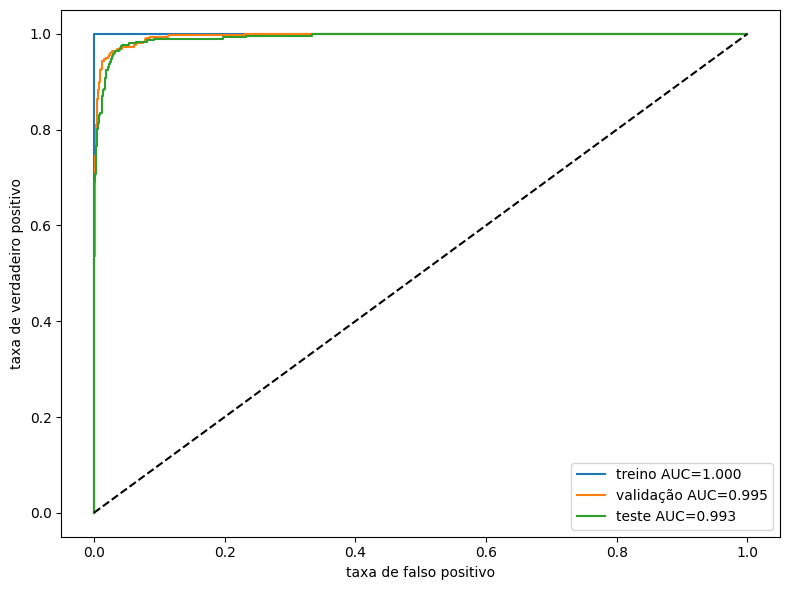

In [28]:
def curva(y, proba, rotulo):
    fpr, tpr, _ = roc_curve(y, proba)
    auc = roc_auc_score(y, proba)
    plt.plot(fpr, tpr, label="%s AUC=%.3f" % (rotulo, auc))
    return metricas(y, proba)


plt.figure(figsize=(8, 6))
for rotulo, X, y in ("treino", X_treino, y_treino), ("validação", X_valid, y_valid), ("teste", X_teste, y_teste):
    print(rotulo, curva(y, melhor.predict_proba(X)[:, 1], rotulo))
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("taxa de falso positivo")
plt.ylabel("taxa de verdadeiro positivo")
plt.legend()
plt.tight_layout()
plt.show()

## Máquina nova

O arquivo `novos_dados.csv` traz só os sensores, na mesma ordem do treino.
O scaler do treino prepara a linha; `predict` devolve a classe (0 ou 1)
e `predict_proba` a chance de precisar de manutenção.

In [29]:
nova = pd.read_csv("novos_dados.csv")
nova_x = scaler.transform(nova[sensores] if set(sensores) <= set(nova.columns) else nova)
classe = melhor.predict(nova_x)
chance = melhor.predict_proba(nova_x)[:, 1]
print("classe:", classe)
print("chance de manutenção:", np.round(chance, 3))

classe: [0]
chance de manutenção: [0.]


c:\Users\fabri\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
